In [1]:

# %pip install pandas numpy sqlalchemy psycopg2-binary scipy statsmodels scikit-learn matplotlib seaborn jupyter


In [2]:
from getpass import getpass
from sqlalchemy import URL, create_engine
from sqlalchemy import text

In [3]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL, text
from getpass import getpass

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:

# PostgreSQL connection details

host = "localhost"
port = 5432
database = "oil_gas_analytics"
username = "postgres"

# Enter your password securely
password = getpass("Enter your PostgreSQL password: ")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=username,
    password=password,
    host=host,
    port=port,
    database=database
)

engine = create_engine(connection_url)

# Test connection
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT version();"))
        print("PostgreSQL connection successful.")
        print(result.scalar())

except Exception as error:
    print("Connection failed:")
    print(error)


Enter your PostgreSQL password:  ········


PostgreSQL connection successful.
PostgreSQL 18.4 on x86_64-windows, compiled by msvc-19.44.35226, 64-bit


In [5]:
# Inspect the analytical schema
query = """
SELECT
    table_name,
    table_type
FROM information_schema.tables
WHERE table_schema = 'analytics'
ORDER BY table_type, table_name;
"""

schema_objects = pd.read_sql(query, engine)

display(schema_objects)


,table_name,table_type
0,daily_operating_costs,BASE TABLE
1,date_dimension,BASE TABLE
2,equipment,BASE TABLE
3,equipment_maintenance,BASE TABLE
4,hse_incidents,BASE TABLE
5,oil_gas_fields,BASE TABLE
6,operators_contractors,BASE TABLE
7,production_facilities,BASE TABLE
8,production_records,BASE TABLE
9,wells,BASE TABLE


In [6]:
# Verify the production data
production_df = pd.read_sql(
    "SELECT * FROM analytics.vw_production_daily LIMIT 10;",
    engine
)

display(production_df)

print("Rows retrieved:", len(production_df))
print("Columns:", production_df.columns.tolist())


,production_date,field_id,field_name,facility_id,facility_name,production_records,active_wells,total_oil_produced_bbl,total_gas_produced_mscf,total_water_produced_bbl,total_production_target_bbl,total_actual_production_bbl,total_production_variance_bbl,production_target_achievement_pct,weighted_water_cut_pct,total_operating_hours,total_downtime_hours
0,2024-01-01,1,Aquila Field,1,Aquila Platform,8,6,"1,144.00",208.48,497.92,"1,369.24","1,144.00",-225.24,83.55,30.33,180.47,11.53
1,2024-01-01,4,Dorado Field,4,Dorado CPF,1,1,154.60,10.42,28.72,192.21,154.60,-37.61,80.43,15.67,21.78,2.22
2,2024-01-01,6,Falcon Field,6,Falcon Flow Station,2,2,113.02,19.85,40.92,129.78,113.02,-16.76,87.09,26.58,46.58,1.42
3,2024-01-01,7,Garnet Field,7,Garnet Flow Station,9,6,815.69,98.41,433.12,933.99,815.69,-118.30,87.33,34.68,206.12,9.88
4,2024-01-01,8,Helios Field,8,Helios Platform,3,3,662.61,89.15,208.58,667.72,662.61,-5.12,99.23,23.94,65.57,6.43
5,2024-01-01,9,Indigo Field,9,Indigo Platform,6,5,"1,006.66",151.98,446.72,"1,206.82","1,006.66",-200.16,83.41,30.74,132.97,11.03
6,2024-01-01,11,Kestrel Field,11,Kestrel Platform,4,3,139.57,78.93,21.91,343.29,139.57,-203.72,40.66,13.57,29.40,66.60
7,2024-01-01,12,Lumen Field,12,Lumen CPF,2,2,0.00,0.00,0.00,232.90,0.00,-232.90,0.00,NaN,4.31,43.69
8,2024-01-01,13,Meridian Field,2,Beryl Flow Station,1,1,0.00,0.00,0.00,42.84,0.00,-42.84,0.00,NaN,4.90,19.10
9,2024-01-01,13,Meridian Field,6,Falcon Flow Station,1,1,115.53,33.36,84.32,123.39,115.53,-7.86,93.63,42.19,23.64,0.36


Rows retrieved: 10
Columns: ['production_date', 'field_id', 'field_name', 'facility_id', 'facility_name', 'production_records', 'active_wells', 'total_oil_produced_bbl', 'total_gas_produced_mscf', 'total_water_produced_bbl', 'total_production_target_bbl', 'total_actual_production_bbl', 'total_production_variance_bbl', 'production_target_achievement_pct', 'weighted_water_cut_pct', 'total_operating_hours', 'total_downtime_hours']


In [7]:
#  Load the complete production dataset


production_df = pd.read_sql_query(
    "SELECT * FROM analytics.vw_production_daily;",
    engine
)

print("Production dataset loaded successfully.")
print("Dataset shape:", production_df.shape)

display(production_df.head())


Production dataset loaded successfully.
Dataset shape: (19588, 17)


,production_date,field_id,field_name,facility_id,facility_name,production_records,active_wells,total_oil_produced_bbl,total_gas_produced_mscf,total_water_produced_bbl,total_production_target_bbl,total_actual_production_bbl,total_production_variance_bbl,production_target_achievement_pct,weighted_water_cut_pct,total_operating_hours,total_downtime_hours
0,2024-01-01,1,Aquila Field,1,Aquila Platform,8,6,"1,144.00",208.48,497.92,"1,369.24","1,144.00",-225.24,83.55,30.33,180.47,11.53
1,2024-01-02,1,Aquila Field,1,Aquila Platform,4,3,564.02,77.67,157.58,644.89,564.02,-80.87,87.46,21.84,92.92,3.08
2,2024-01-03,1,Aquila Field,1,Aquila Platform,6,6,750.47,77.51,201.24,"1,162.61",750.47,-412.14,64.55,21.15,113.73,30.27
3,2024-01-05,1,Aquila Field,1,Aquila Platform,6,4,741.00,233.08,361.00,941.74,741.00,-200.75,78.68,32.76,133.61,10.39
4,2024-01-06,1,Aquila Field,1,Aquila Platform,3,3,234.46,29.75,61.42,251.60,234.46,-17.15,93.19,20.76,65.00,7.00


In [8]:
# 1. Inspect data types and non-null counts
print("DATASET INFORMATION")
production_df.info()

# 2. Check missing values
print("\nMISSING VALUES")
missing_values = production_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(production_df)
    ) * 100
})

display(missing_summary)

# 3. Check duplicate rows
print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", production_df.duplicated().sum())

# 4. Check date column
print("\nDATE COLUMN TYPE")
print(production_df["production_date"].dtype)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19588 entries, 0 to 19587
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   production_date                    19588 non-null  object 
 1   field_id                           19588 non-null  int64  
 2   field_name                         19588 non-null  object 
 3   facility_id                        19588 non-null  int64  
 4   facility_name                      19588 non-null  object 
 5   production_records                 19588 non-null  int64  
 6   active_wells                       19588 non-null  int64  
 7   total_oil_produced_bbl             19588 non-null  float64
 8   total_gas_produced_mscf            19588 non-null  float64
 9   total_water_produced_bbl           19588 non-null  float64
 10  total_production_target_bbl        19588 non-null  float64
 11  total_actual_production_bbl       

,Missing Values,Missing Percentage
production_date,0,0.00
field_id,0,0.00
field_name,0,0.00
facility_id,0,0.00
facility_name,0,0.00
production_records,0,0.00
active_wells,0,0.00
total_oil_produced_bbl,0,0.00
total_gas_produced_mscf,0,0.00
total_water_produced_bbl,0,0.00



DUPLICATE ROWS
Number of duplicate rows: 0

DATE COLUMN TYPE
object


In [9]:
# Convert production_date to pandas datetime for reliable time-series operations
production_df["production_date"] = pd.to_datetime(
    production_df["production_date"],
    errors="coerce"
)

if production_df["production_date"].isna().any():
    raise ValueError("Some production_date values could not be parsed.")

print("Date conversion completed.")
print("Data type:", production_df["production_date"].dtype)
display(production_df[["production_date"]].head())

Date conversion completed.
Data type: datetime64[ns]


,production_date
0,2024-01-01
1,2024-01-02
2,2024-01-03
3,2024-01-05
4,2024-01-06


In [10]:
# Select numerical variables for descriptive analysis

numeric_columns = [
    "production_records",
    "active_wells",
    "total_oil_produced_bbl",
    "total_gas_produced_mscf",
    "total_water_produced_bbl",
    "total_production_target_bbl",
    "total_actual_production_bbl",
    "total_production_variance_bbl",
    "production_target_achievement_pct",
    "weighted_water_cut_pct",
    "total_operating_hours",
    "total_downtime_hours"
]

# Generate descriptive statistics
descriptive_stats = production_df[numeric_columns].describe().T

# Display results
display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
production_records,"19,588.00",2.55,1.96,1.00,1.00,2.00,3.00,14.00
active_wells,"19,588.00",2.07,1.48,1.00,1.00,1.00,3.00,9.00
total_oil_produced_bbl,"19,588.00",229.85,237.36,0.00,69.55,153.60,308.14,"2,078.98"
total_gas_produced_mscf,"19,588.00",39.87,46.40,0.00,9.46,24.08,53.53,532.10
total_water_produced_bbl,"19,588.00",96.03,113.01,0.00,16.85,52.51,139.13,"1,062.02"
total_production_target_bbl,"19,588.00",322.82,281.83,20.07,127.90,220.41,433.91,"2,620.68"
total_actual_production_bbl,"19,588.00",229.87,237.37,0.00,69.58,153.61,308.20,"2,078.98"
total_production_variance_bbl,"19,588.00",-92.94,107.06,"-1,034.17",-137.18,-56.00,-18.58,193.74
production_target_achievement_pct,"19,588.00",67.58,31.60,0.00,53.45,78.40,89.22,268.09
weighted_water_cut_pct,"18,080.00",27.32,13.22,0.00,18.21,24.98,34.63,78.99


In [11]:
# Calculate additional statistical measures

additional_stats = pd.DataFrame(index=numeric_columns)

additional_stats["Variance"] = production_df[numeric_columns].var()
additional_stats["Range"] = (
    production_df[numeric_columns].max()
    - production_df[numeric_columns].min()
)
additional_stats["Skewness"] = production_df[numeric_columns].skew()
additional_stats["Kurtosis"] = production_df[numeric_columns].kurt()

display(additional_stats)

,Variance,Range,Skewness,Kurtosis
production_records,3.84,13.00,1.49,1.99
active_wells,2.19,8.00,1.46,1.55
total_oil_produced_bbl,"56,339.74","2,078.98",1.91,4.80
total_gas_produced_mscf,"2,152.87",532.10,2.44,9.32
total_water_produced_bbl,"12,770.71","1,062.02",2.00,5.25
total_production_target_bbl,"79,427.75","2,600.61",1.80,4.12
total_actual_production_bbl,"56,342.39","2,078.98",1.91,4.79
total_production_variance_bbl,"11,460.84","1,227.91",-1.95,5.42
production_target_achievement_pct,998.55,268.09,-0.95,-0.06
weighted_water_cut_pct,174.74,78.99,0.87,0.97


In [12]:
# Compare mean and median

# Compare mean and median

mean_median_comparison = pd.DataFrame({
    "Mean": production_df[numeric_columns].mean(),
    "Median": production_df[numeric_columns].median()
})

mean_median_comparison["Difference"] = (
    mean_median_comparison["Mean"]
    - mean_median_comparison["Median"]
)

display(mean_median_comparison)

,Mean,Median,Difference
production_records,2.55,2.00,0.55
active_wells,2.07,1.00,1.07
total_oil_produced_bbl,229.85,153.60,76.25
total_gas_produced_mscf,39.87,24.08,15.79
total_water_produced_bbl,96.03,52.51,43.52
total_production_target_bbl,322.82,220.41,102.40
total_actual_production_bbl,229.87,153.61,76.26
total_production_variance_bbl,-92.94,-56.00,-36.94
production_target_achievement_pct,67.58,78.40,-10.82
weighted_water_cut_pct,27.32,24.98,2.33


In [13]:
# 1. Investigate negative downtime
negative_downtime = production_df[
    production_df["total_downtime_hours"] < 0
].copy()

print("NEGATIVE DOWNTIME RECORDS")
print("Number of records:", len(negative_downtime))

display(
    negative_downtime[
        [
            "production_date",
            "field_name",
            "facility_name",
            "total_operating_hours",
            "total_downtime_hours"
        ]
    ]
)


# 2. Investigate target achievement above 100%
high_achievement = production_df[
    production_df["production_target_achievement_pct"] > 100
].copy()

print("\nTARGET ACHIEVEMENT ABOVE 100%")
print("Number of records:", len(high_achievement))

display(
    high_achievement[
        [
            "production_date",
            "field_name",
            "facility_name",
            "total_production_target_bbl",
            "total_actual_production_bbl",
            "production_target_achievement_pct"
        ]
    ].sort_values(
        "production_target_achievement_pct",
        ascending=False
    ).head(10)
)


# 3. Validate production variance
production_df["calculated_variance"] = (
    production_df["total_actual_production_bbl"]
    - production_df["total_production_target_bbl"]
)

production_df["variance_difference"] = (
    production_df["total_production_variance_bbl"]
    - production_df["calculated_variance"]
)

print("\nPRODUCTION VARIANCE VALIDATION")
print(
    "Records with a variance difference greater than 0.01 bbl:",
    (production_df["variance_difference"].abs() > 0.01).sum()
)

print(
    "Largest absolute variance difference:",
    production_df["variance_difference"].abs().max()
)

display(
    production_df[
        production_df["variance_difference"].abs() > 0.01
    ][
        [
            "production_date",
            "field_name",
            "total_production_target_bbl",
            "total_actual_production_bbl",
            "total_production_variance_bbl",
            "calculated_variance",
            "variance_difference"
        ]
    ].head(10)
)

NEGATIVE DOWNTIME RECORDS
Number of records: 2


,production_date,field_name,facility_name,total_operating_hours,total_downtime_hours
6252,2025-08-14,Garnet Field,Garnet Flow Station,91.74,-0.27
8681,2026-07-06,Indigo Field,Indigo Platform,45.01,-1.42



TARGET ACHIEVEMENT ABOVE 100%
Number of records: 1470


,production_date,field_name,facility_name,total_production_target_bbl,total_actual_production_bbl,production_target_achievement_pct
1553,2025-05-15,Beryl Field,Beryl Flow Station,50.18,134.53,268.09
10946,2025-01-31,Lumen Field,Lumen CPF,155.52,343.77,221.05
17622,2025-02-26,Orion Field,Beryl Flow Station,104.15,144.54,138.78
15826,2026-01-23,Nova Field,Lumen CPF,193.95,261.09,134.62
2177,2024-03-26,Cobalt Field,Cobalt Production Hub,169.56,226.43,133.54
16926,2024-07-03,Orion Field,Indigo Platform,113.92,152.07,133.49
19514,2026-12-05,Orion Field,Cobalt Production Hub,590.19,783.93,132.83
13127,2025-06-27,Meridian Field,Falcon Flow Station,118.65,156.73,132.09
15824,2026-01-22,Nova Field,Lumen CPF,194.60,256.51,131.81
4884,2024-06-11,Falcon Field,Falcon Flow Station,128.13,167.30,130.57



PRODUCTION VARIANCE VALIDATION
Records with a variance difference greater than 0.01 bbl: 3840
Largest absolute variance difference: 0.050000000000125056


,production_date,field_name,total_production_target_bbl,total_actual_production_bbl,total_production_variance_bbl,calculated_variance,variance_difference
4,2024-01-06,Aquila Field,251.60,234.46,-17.15,-17.14,-0.01
5,2024-01-07,Aquila Field,"1,297.45","1,152.26",-145.17,-145.19,0.02
8,2024-01-10,Aquila Field,700.54,611.79,-88.76,-88.75,-0.01
10,2024-01-12,Aquila Field,572.19,555.77,-16.41,-16.42,0.01
11,2024-01-13,Aquila Field,260.98,213.56,-47.41,-47.42,0.01
14,2024-01-16,Aquila Field,"1,223.02","1,144.64",-78.39,-78.38,-0.01
15,2024-01-17,Aquila Field,620.30,634.92,14.61,14.62,-0.01
16,2024-01-18,Aquila Field,638.74,426.50,-212.23,-212.24,0.01
17,2024-01-19,Aquila Field,541.86,361.38,-180.46,-180.48,0.02
18,2024-01-20,Aquila Field,565.36,522.51,-42.84,-42.85,0.01


In [14]:
# Count distinct field-facility combinations
field_facility_pairs = (
    production_df.groupby(
        ["field_id", "field_name", "facility_id", "facility_name"]
    )
    .agg(
        production_observations=("production_date", "count"),
        total_oil=("total_oil_produced_bbl", "sum"),
        total_actual=("total_actual_production_bbl", "sum")
    )
    .reset_index()
    .sort_values(
        ["field_id", "facility_id"]
    )
)

print("Number of distinct field-facility combinations:",
      len(field_facility_pairs))

display(field_facility_pairs)

Number of distinct field-facility combinations: 30


,field_id,field_name,facility_id,facility_name,production_observations,total_oil,total_actual
0,1,Aquila Field,1,Aquila Platform,1087,"594,592.09","594,592.09"
1,2,Beryl Field,2,Beryl Flow Station,1018,"134,269.14","134,362.23"
2,3,Cobalt Field,3,Cobalt Production Hub,897,"125,715.53","125,715.53"
3,4,Dorado Field,4,Dorado CPF,656,"71,371.70","71,371.70"
4,5,Emerald Field,5,Emerald Platform,1088,"239,202.46","239,202.46"
5,6,Falcon Field,6,Falcon Flow Station,919,"111,059.09","111,237.01"
6,7,Garnet Field,7,Garnet Flow Station,1092,"466,900.74","466,900.74"
7,8,Helios Field,8,Helios Platform,1080,"534,680.75","534,680.75"
8,9,Indigo Field,9,Indigo Platform,1012,"405,902.51","405,902.51"
9,10,Jasper Field,10,Jasper Production Hub,803,"112,988.46","112,988.46"


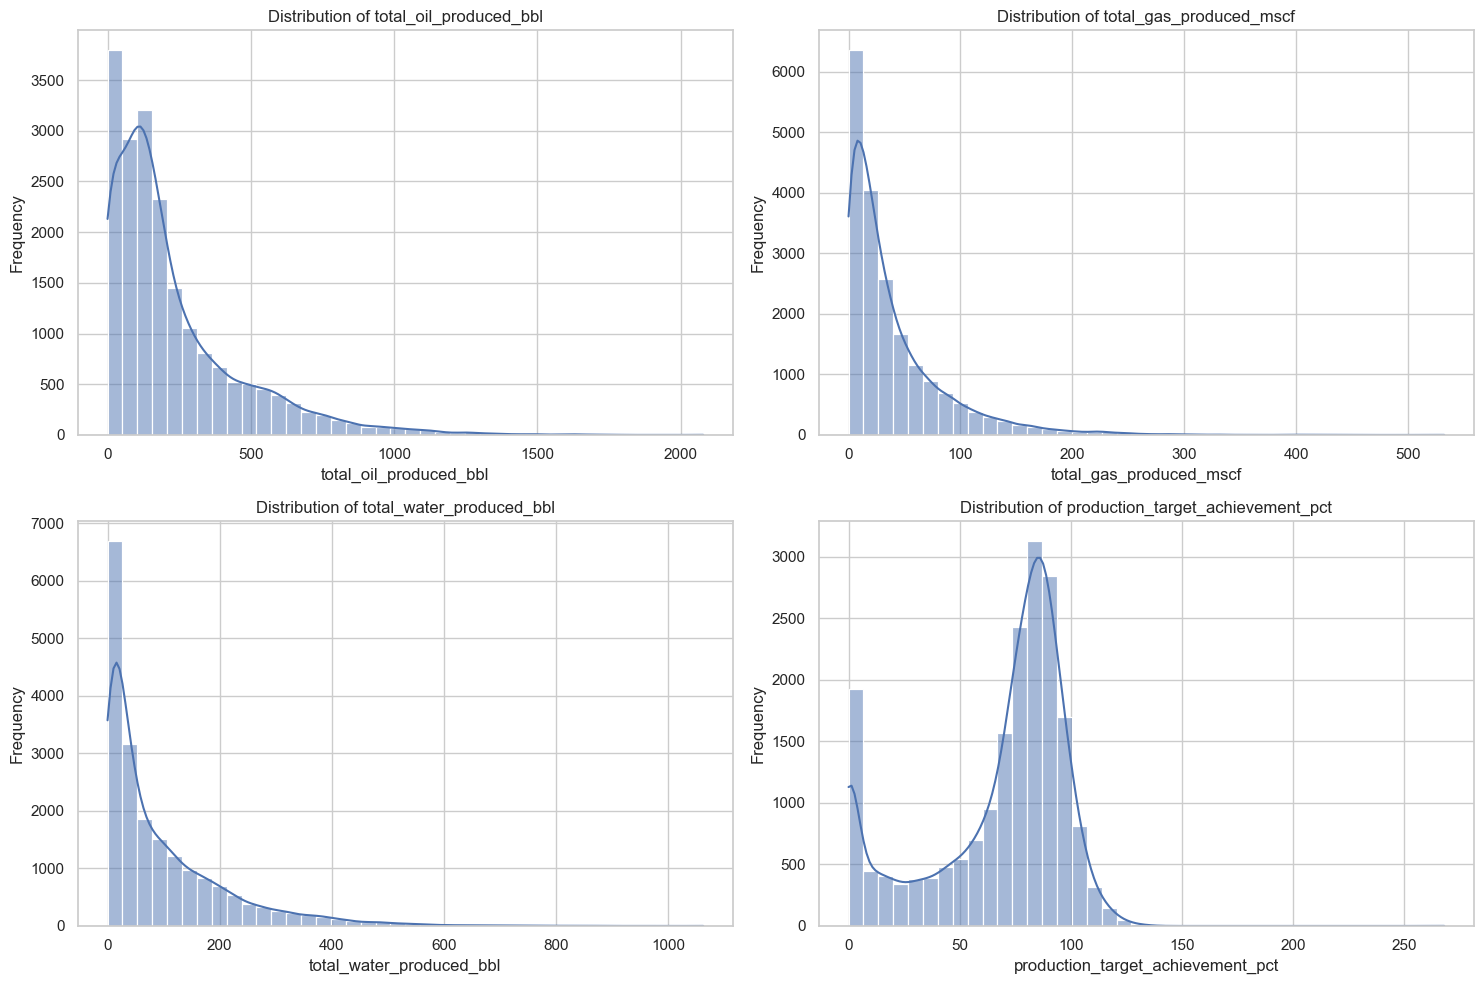

In [15]:
# Hostograms of production variables

# Select variables for histogram analysis

histogram_columns = [
    "total_oil_produced_bbl",
    "total_gas_produced_mscf",
    "total_water_produced_bbl",
    "production_target_achievement_pct"
]

# Create a 2x2 histogram layout
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, ax in zip(histogram_columns, axes.flatten()):

    sns.histplot(
        data=production_df,
        x=column,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

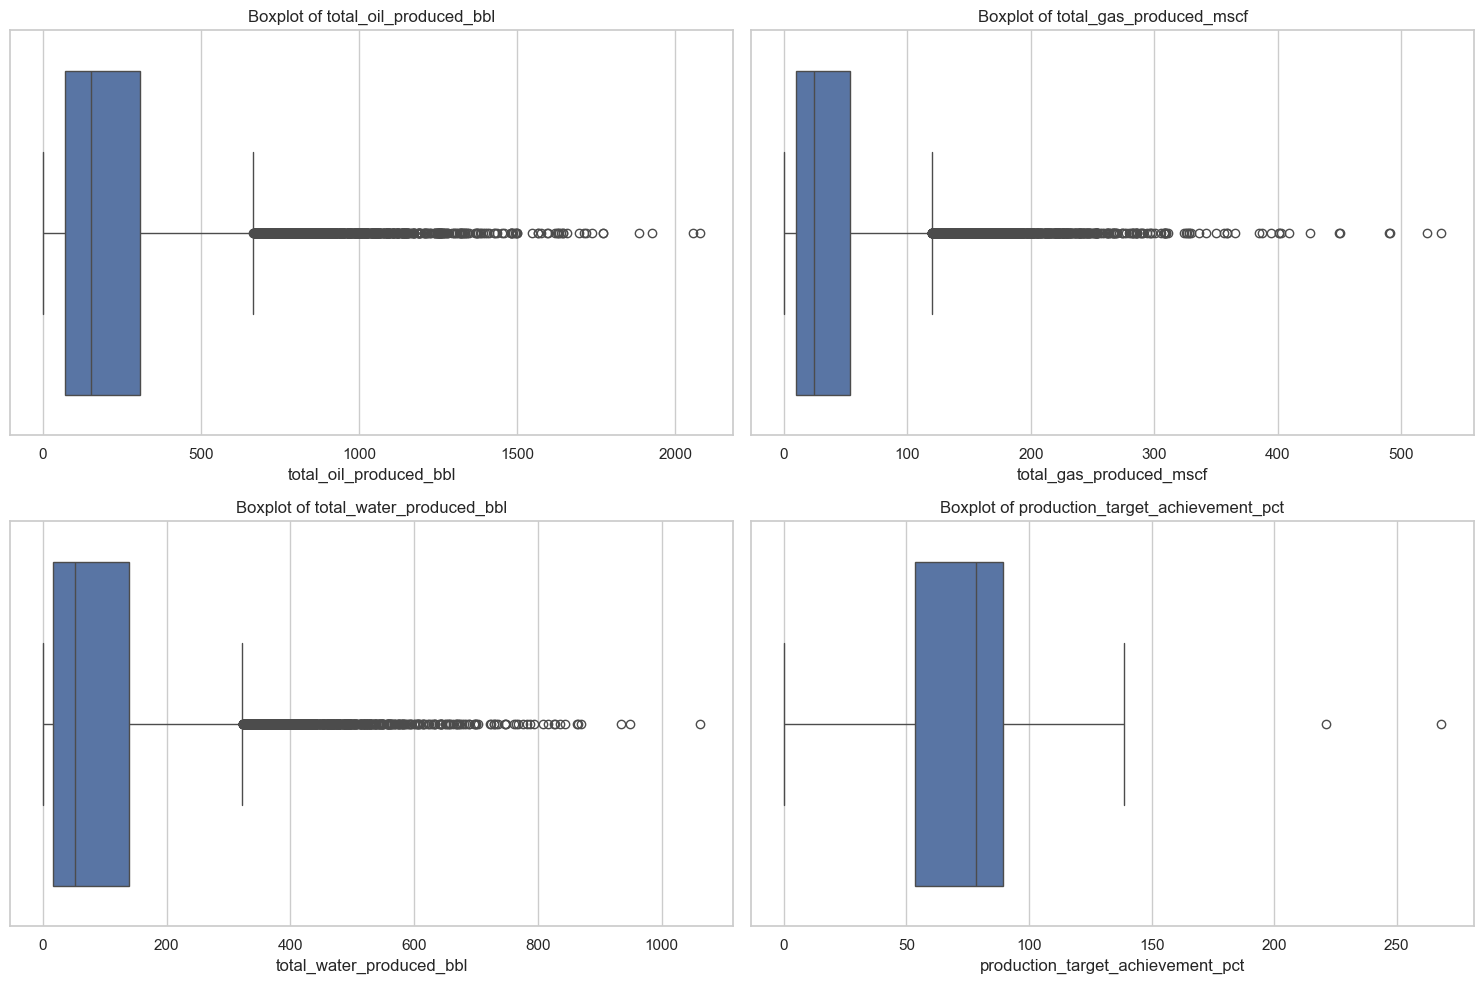

In [16]:
# Boxplots of production variables
# Create boxplots for production variables

boxplot_columns = [
    "total_oil_produced_bbl",
    "total_gas_produced_mscf",
    "total_water_produced_bbl",
    "production_target_achievement_pct"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, ax in zip(boxplot_columns, axes.flatten()):

    sns.boxplot(
        data=production_df,
        x=column,
        ax=ax
    )

    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [17]:
# Quantify potential outliers

# Calculate outliers using the IQR method

outlier_results = []

for column in boxplot_columns:

    Q1 = production_df[column].quantile(0.25)
    Q3 = production_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = production_df[
        (production_df[column] < lower_bound) |
        (production_df[column] > upper_bound)
    ]

    outlier_results.append({
        "Variable": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(production_df)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,total_oil_produced_bbl,-288.35,666.03,1209,6.17
1,total_gas_produced_mscf,-56.65,119.64,1278,6.52
2,total_water_produced_bbl,-166.57,322.56,1062,5.42
3,production_target_achievement_pct,-0.20,142.88,2,0.01


In [18]:
# Confirm the date column remains datetime after data-quality checks
production_df["production_date"] = pd.to_datetime(
    production_df["production_date"],
    errors="coerce"
)

if production_df["production_date"].isna().any():
    raise ValueError("Invalid production dates detected.")

print("Production date dtype:", production_df["production_date"].dtype)
display(production_df[["production_date"]].head())

Production date dtype: datetime64[ns]


,production_date
0,2024-01-01
1,2024-01-02
2,2024-01-03
3,2024-01-05
4,2024-01-06


In [19]:
# Create a monthly grouping column
production_df["month"] = (
    production_df["production_date"].dt.to_period("M")
)

# Aggregate production data monthly
monthly_production = (
    production_df
    .groupby("month")
    .agg(
        total_oil=("total_oil_produced_bbl", "sum"),
        total_gas=("total_gas_produced_mscf", "sum"),
        total_water=("total_water_produced_bbl", "sum"),
        total_target=("total_production_target_bbl", "sum"),
        total_actual=("total_actual_production_bbl", "sum"),
        total_operating_hours=("total_operating_hours", "sum"),
        total_downtime_hours=("total_downtime_hours", "sum"),
        production_days=("production_date", "nunique")
    )
    .reset_index()
)

# Convert month back to timestamp for plotting
monthly_production["month"] = (
    monthly_production["month"].dt.to_timestamp()
)

# Calculate weighted performance indicators
monthly_production["target_achievement_pct"] = (
    monthly_production["total_actual"]
    / monthly_production["total_target"]
) * 100

monthly_production["water_cut_pct"] = (
    monthly_production["total_water"]
    / (
        monthly_production["total_oil"]
        + monthly_production["total_water"]
    )
) * 100

monthly_production["production_variance"] = (
    monthly_production["total_actual"]
    - monthly_production["total_target"]
)

display(monthly_production.round(2))

print("Monthly observations:", len(monthly_production))

,month,total_oil,total_gas,total_water,total_target,total_actual,total_operating_hours,total_downtime_hours,production_days,target_achievement_pct,water_cut_pct,production_variance
0,2024-01-01,"131,091.65","23,182.03","54,026.19","186,934.66","131,091.65","25,960.01","8,047.99",31,70.13,29.18,"-55,843.01"
1,2024-02-01,"119,352.67","20,809.91","50,941.50","169,089.15","119,352.67","24,473.30","7,110.70",29,70.59,29.91,"-49,736.48"
2,2024-03-01,"133,860.73","22,954.43","53,303.59","188,536.41","133,860.73","26,563.67","7,756.33",31,71.00,28.48,"-54,675.68"
3,2024-04-01,"132,336.58","23,004.21","54,696.88","183,477.47","132,336.58","25,406.96","7,521.04",30,72.13,29.24,"-51,140.89"
4,2024-05-01,"138,413.14","24,797.16","58,579.16","193,591.30","138,413.14","26,671.60","7,864.40",31,71.50,29.74,"-55,178.16"
5,2024-06-01,"121,166.79","20,513.70","50,605.02","169,166.10","121,166.79","24,330.52","6,989.48",30,71.63,29.46,"-47,999.31"
6,2024-07-01,"136,301.16","23,787.56","55,911.08","190,104.75","136,301.16","27,121.33","7,990.67",31,71.70,29.09,"-53,803.59"
7,2024-08-01,"128,950.85","22,953.41","53,341.54","180,152.19","128,950.85","26,006.98","7,542.76",31,71.58,29.26,"-51,201.34"
8,2024-09-01,"129,330.28","21,986.31","55,223.01","177,769.25","129,330.28","25,625.86","6,894.14",30,72.75,29.92,"-48,438.97"
9,2024-10-01,"134,857.18","23,876.97","56,335.85","187,530.04","134,857.18","27,444.06","7,880.49",31,71.91,29.47,"-52,672.86"


Monthly observations: 36


In [20]:
# Annual Comparison
# Extract year from the month column
monthly_production["year"] = monthly_production["month"].dt.year

# Aggregate monthly figures into annual figures
annual_production = (
    monthly_production.groupby("year")
    .agg(
        total_oil=("total_oil", "sum"),
        total_gas=("total_gas", "sum"),
        total_water=("total_water", "sum"),
        total_target=("total_target", "sum"),
        total_actual=("total_actual", "sum"),
        total_operating_hours=("total_operating_hours", "sum"),
        total_downtime_hours=("total_downtime_hours", "sum")
    )
    .reset_index()
)

# Calculate annual performance indicators
annual_production["target_achievement_pct"] = (
    annual_production["total_actual"]
    / annual_production["total_target"]
) * 100

annual_production["water_cut_pct"] = (
    annual_production["total_water"]
    / (annual_production["total_oil"] + annual_production["total_water"])
) * 100

annual_production["downtime_pct"] = (
    annual_production["total_downtime_hours"]
    / (
        annual_production["total_operating_hours"]
        + annual_production["total_downtime_hours"]
    )
) * 100

display(annual_production.round(2))

,year,total_oil,total_gas,total_water,total_target,total_actual,total_operating_hours,total_downtime_hours,target_achievement_pct,water_cut_pct,downtime_pct
0,2024,"1,551,744.70","270,005.82","645,616.66","2,171,392.52","1,551,744.70","310,035.84","90,470.45",71.46,29.38,22.59
1,2025,"1,486,518.52","258,017.67","629,246.43","2,101,115.44","1,486,860.88","306,594.98","91,656.49",70.77,29.74,23.01
2,2026,"1,464,036.32","252,955.44","606,090.67","2,050,822.55","1,464,170.94","310,998.17","90,229.42",71.39,29.28,22.49


In [21]:
# Correlation Analysis

# Select variables for correlation analysis
correlation_df = production_df[
    [
        "total_oil_produced_bbl",
        "total_gas_produced_mscf",
        "total_water_produced_bbl",
        "total_operating_hours",
        "total_downtime_hours",
        "weighted_water_cut_pct",
        "production_target_achievement_pct"
    ]
].copy()

# Calculate Pearson correlation
pearson_corr = correlation_df.corr(method="pearson")

# Calculate Spearman correlation
spearman_corr = correlation_df.corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))

PEARSON CORRELATION


,total_oil_produced_bbl,total_gas_produced_mscf,total_water_produced_bbl,total_operating_hours,total_downtime_hours,weighted_water_cut_pct,production_target_achievement_pct
total_oil_produced_bbl,1.00,0.90,0.79,0.80,0.01,0.01,0.40
total_gas_produced_mscf,0.90,1.00,0.71,0.71,0.01,0.02,0.35
total_water_produced_bbl,0.79,0.71,1.00,0.74,0.11,0.48,0.32
total_operating_hours,0.80,0.71,0.74,1.00,0.15,0.10,0.34
total_downtime_hours,0.01,0.01,0.11,0.15,1.00,0.10,-0.62
weighted_water_cut_pct,0.01,0.02,0.48,0.10,0.10,1.00,-0.03
production_target_achievement_pct,0.40,0.35,0.32,0.34,-0.62,-0.03,1.00


SPEARMAN CORRELATION


,total_oil_produced_bbl,total_gas_produced_mscf,total_water_produced_bbl,total_operating_hours,total_downtime_hours,weighted_water_cut_pct,production_target_achievement_pct
total_oil_produced_bbl,1.00,0.93,0.87,0.82,0.01,0.12,0.45
total_gas_produced_mscf,0.93,1.00,0.81,0.78,-0.00,0.11,0.43
total_water_produced_bbl,0.87,0.81,1.00,0.75,0.01,0.60,0.40
total_operating_hours,0.82,0.78,0.75,1.00,0.14,0.17,0.31
total_downtime_hours,0.01,-0.00,0.01,0.14,1.00,0.11,-0.70
weighted_water_cut_pct,0.12,0.11,0.60,0.17,0.11,1.00,-0.03
production_target_achievement_pct,0.45,0.43,0.40,0.31,-0.70,-0.03,1.00


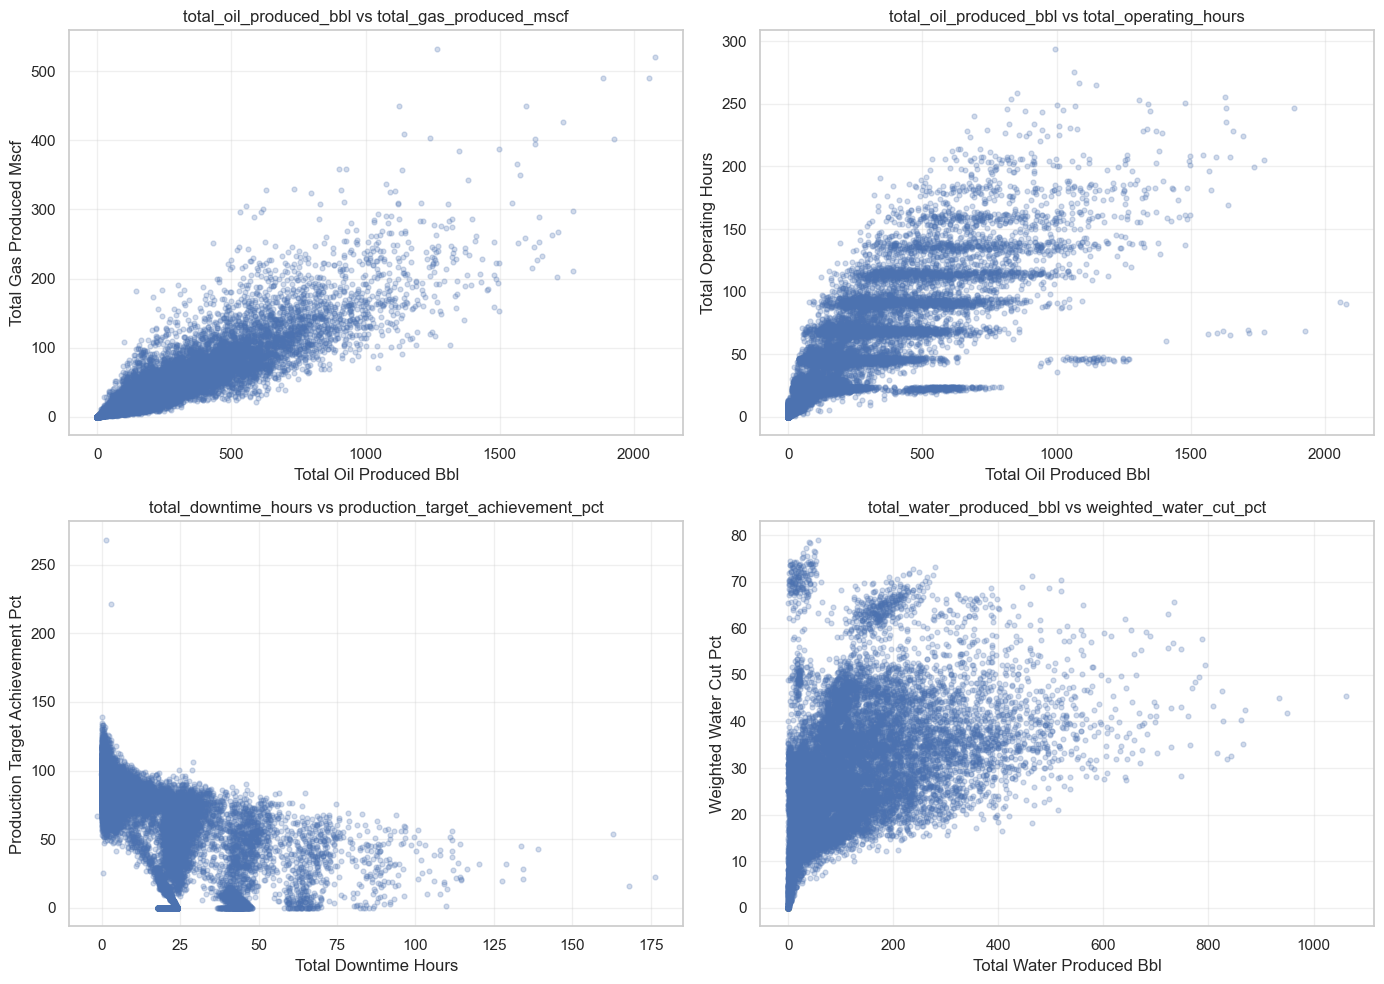

In [22]:
# Visualize relationship

import matplotlib.pyplot as plt

# Relationships to visualize
relationships = [
    ("total_oil_produced_bbl", "total_gas_produced_mscf"),
    ("total_oil_produced_bbl", "total_operating_hours"),
    ("total_downtime_hours", "production_target_achievement_pct"),
    ("total_water_produced_bbl", "weighted_water_cut_pct")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (x, y) in zip(axes.flatten(), relationships):

    plot_data = production_df[[x, y]].dropna()

    ax.scatter(
        plot_data[x],
        plot_data[y],
        alpha=0.25,
        s=12
    )

    ax.set_xlabel(x.replace("_", " ").title())
    ax.set_ylabel(y.replace("_", " ").title())
    ax.set_title(f"{x} vs {y}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Statistical significance testing for selected correlations
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests
import pandas as pd

relationships = [
    ("Oil vs Gas", "total_oil_produced_bbl", "total_gas_produced_mscf"),
    ("Oil vs Operating Hours", "total_oil_produced_bbl", "total_operating_hours"),
    ("Downtime vs Target Achievement", "total_downtime_hours",
     "production_target_achievement_pct"),
    ("Water vs Water Cut", "total_water_produced_bbl", "weighted_water_cut_pct")
]

results = []

for name, x, y in relationships:
    data = production_df[[x, y]].dropna()

    if len(data) < 3 or data[x].nunique() < 2 or data[y].nunique() < 2:
        raise ValueError(f"Insufficient variation or observations for: {name}")

    pearson_r, pearson_p = pearsonr(data[x], data[y])
    spearman_rho, spearman_p = spearmanr(data[x], data[y])

    results.append({
        "Relationship": name,
        "Sample Size": len(data),
        "Pearson r": pearson_r,
        "Pearson p-value": pearson_p,
        "Spearman rho": spearman_rho,
        "Spearman p-value": spearman_p
    })

significance_results = pd.DataFrame(results)

# Holm correction across all eight p-values (four Pearson and four Spearman tests)
p_value_columns = ["Pearson p-value", "Spearman p-value"]
all_p_values = significance_results[p_value_columns].to_numpy().ravel()

reject, adjusted_p_values, _, _ = multipletests(
    all_p_values,
    alpha=0.05,
    method="holm"
)

significance_results["Pearson Holm p-value"] = adjusted_p_values[0::2]
significance_results["Spearman Holm p-value"] = adjusted_p_values[1::2]
significance_results["Pearson Significant (Holm)"] = reject[0::2]
significance_results["Spearman Significant (Holm)"] = reject[1::2]

display(significance_results.round(6))

print(
    "Interpretation note: p-values quantify evidence against zero association; "
    "they do not establish causation. Production observations may be serially "
    "dependent, so conventional correlation-test p-values can overstate "
    "independent information in the sample."
)

,Relationship,Sample Size,Pearson r,Pearson p-value,Spearman rho,Spearman p-value,Pearson Holm p-value,Spearman Holm p-value,Pearson Significant (Holm),Spearman Significant (Holm)
0,Oil vs Gas,19588,0.89,0.00,0.93,0.00,0.00,0.00,True,True
1,Oil vs Operating Hours,19588,0.80,0.00,0.82,0.00,0.00,0.00,True,True
2,Downtime vs Target Achievement,19588,-0.62,0.00,-0.70,0.00,0.00,0.00,True,True
3,Water vs Water Cut,18080,0.48,0.00,0.60,0.00,0.00,0.00,True,True


Interpretation note: p-values quantify evidence against zero association; they do not establish causation. Production observations may be serially dependent, so conventional correlation-test p-values can overstate independent information in the sample.


In [24]:
# Approximate 95% confidence intervals for Pearson correlations
import numpy as np
from scipy.stats import pearsonr, spearmanr
import pandas as pd

relationships = [
    ("Oil vs Gas", "total_oil_produced_bbl", "total_gas_produced_mscf"),
    ("Oil vs Operating Hours", "total_oil_produced_bbl", "total_operating_hours"),
    ("Downtime vs Target Achievement", "total_downtime_hours",
     "production_target_achievement_pct"),
    ("Water vs Water Cut", "total_water_produced_bbl", "weighted_water_cut_pct")
]

results = []

for name, x, y in relationships:
    data = production_df[[x, y]].dropna()
    n = len(data)

    if n <= 3 or data[x].nunique() < 2 or data[y].nunique() < 2:
        raise ValueError(f"Insufficient data for confidence interval: {name}")

    r, pearson_p = pearsonr(data[x], data[y])
    rho, spearman_p = spearmanr(data[x], data[y])

    # Fisher z interval: approximate CI for Pearson's r
    z = np.arctanh(np.clip(r, -0.999999, 0.999999))
    standard_error = 1 / np.sqrt(n - 3)
    lower = np.tanh(z - 1.96 * standard_error)
    upper = np.tanh(z + 1.96 * standard_error)

    results.append({
        "Relationship": name,
        "Sample Size": n,
        "Pearson r": r,
        "Pearson 95% CI Lower": lower,
        "Pearson 95% CI Upper": upper,
        "Pearson p-value": pearson_p,
        "Spearman rho": rho,
        "Spearman p-value": spearman_p
    })

confidence_results = pd.DataFrame(results)
display(confidence_results.round(6))

print(
    "CI limitation: Fisher's z interval is an approximate interval for Pearson's r. "
    "Its usual interpretation relies on independent observations and an "
    "appropriate bivariate sampling model. Daily production records can be "
    "serially dependent, so these intervals should be treated as descriptive "
    "approximations rather than time-series-adjusted inference."
)

for _, row in confidence_results.iterrows():
    print(
        f"{row['Relationship']}: "
        f"Pearson p = {row['Pearson p-value']:.3e}, "
        f"Spearman p = {row['Spearman p-value']:.3e}"
    )

,Relationship,Sample Size,Pearson r,Pearson 95% CI Lower,Pearson 95% CI Upper,Pearson p-value,Spearman rho,Spearman p-value
0,Oil vs Gas,19588,0.89,0.89,0.90,0.00,0.93,0.00
1,Oil vs Operating Hours,19588,0.80,0.79,0.80,0.00,0.82,0.00
2,Downtime vs Target Achievement,19588,-0.62,-0.63,-0.62,0.00,-0.70,0.00
3,Water vs Water Cut,18080,0.48,0.46,0.49,0.00,0.60,0.00


CI limitation: Fisher's z interval is an approximate interval for Pearson's r. Its usual interpretation relies on independent observations and an appropriate bivariate sampling model. Daily production records can be serially dependent, so these intervals should be treated as descriptive approximations rather than time-series-adjusted inference.
Oil vs Gas: Pearson p = 0.000e+00, Spearman p = 0.000e+00
Oil vs Operating Hours: Pearson p = 0.000e+00, Spearman p = 0.000e+00
Downtime vs Target Achievement: Pearson p = 0.000e+00, Spearman p = 0.000e+00
Water vs Water Cut: Pearson p = 0.000e+00, Spearman p = 0.000e+00


In [25]:
# comparing production performance across fields
# Prepare field-level production data

# Aggregate facility observations into daily field-level observations
field_daily = (
    production_df
    .groupby(
        ["production_date", "field_id", "field_name"],
        as_index=False
    )
    .agg(
        daily_oil=("total_oil_produced_bbl", "sum"),
        daily_gas=("total_gas_produced_mscf", "sum"),
        daily_water=("total_water_produced_bbl", "sum"),
        daily_operating_hours=("total_operating_hours", "sum"),
        daily_downtime_hours=("total_downtime_hours", "sum"),
        daily_target=("total_production_target_bbl", "sum"),
        daily_actual=("total_actual_production_bbl", "sum")
    )
)

print("Dataset shape:", field_daily.shape)

print(
    "Number of fields:",
    field_daily["field_name"].nunique()
)

display(
    field_daily.groupby("field_name")
    .agg(
        observation_count=("daily_oil", "count"),
        average_daily_oil=("daily_oil", "mean"),
        median_daily_oil=("daily_oil", "median"),
        total_oil=("daily_oil", "sum")
    )
    .round(2)
    .sort_values("average_daily_oil", ascending=False)
)

Dataset shape: (14739, 10)
Number of fields: 15


,observation_count,average_daily_oil,median_daily_oil,total_oil
field_name,,,,
Orion Field,1074,556.10,438.16,"597,250.00"
Aquila Field,1087,547.00,507.15,"594,592.09"
Helios Field,1080,495.07,450.10,"534,680.75"
Lumen Field,1089,445.80,411.87,"485,476.35"
Garnet Field,1092,427.56,411.10,"466,900.74"
Indigo Field,1012,401.09,364.07,"405,902.51"
Meridian Field,1062,364.28,334.58,"386,864.69"
Emerald Field,1088,219.86,199.84,"239,202.46"
Nova Field,963,146.68,117.49,"141,254.96"


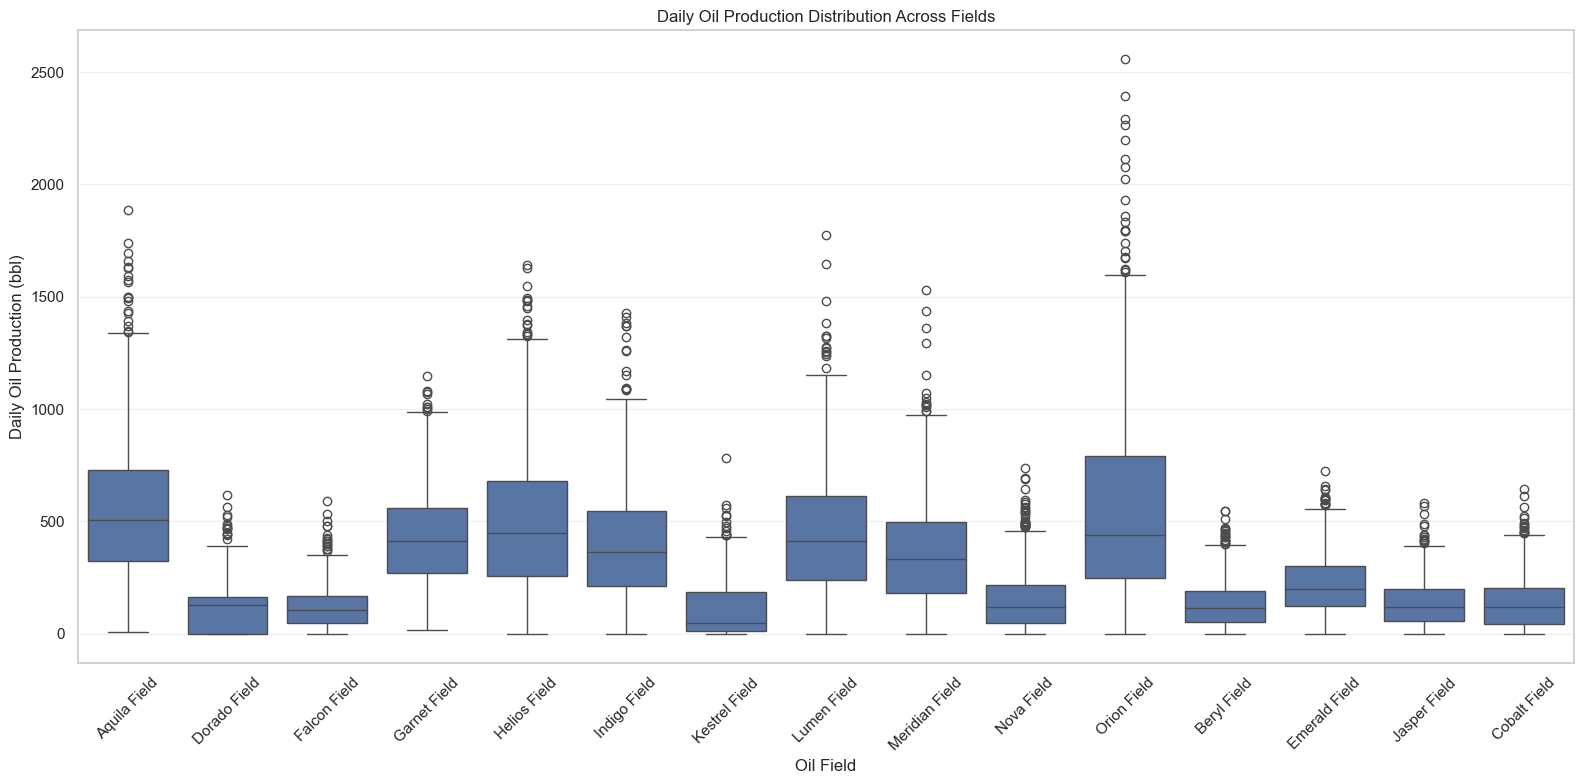

In [26]:
# Before hypothesis testing: visualize field distributions
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=field_daily,
    x="field_name",
    y="daily_oil"
)

plt.title("Daily Oil Production Distribution Across Fields")
plt.xlabel("Oil Field")
plt.ylabel("Daily Oil Production (bbl)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

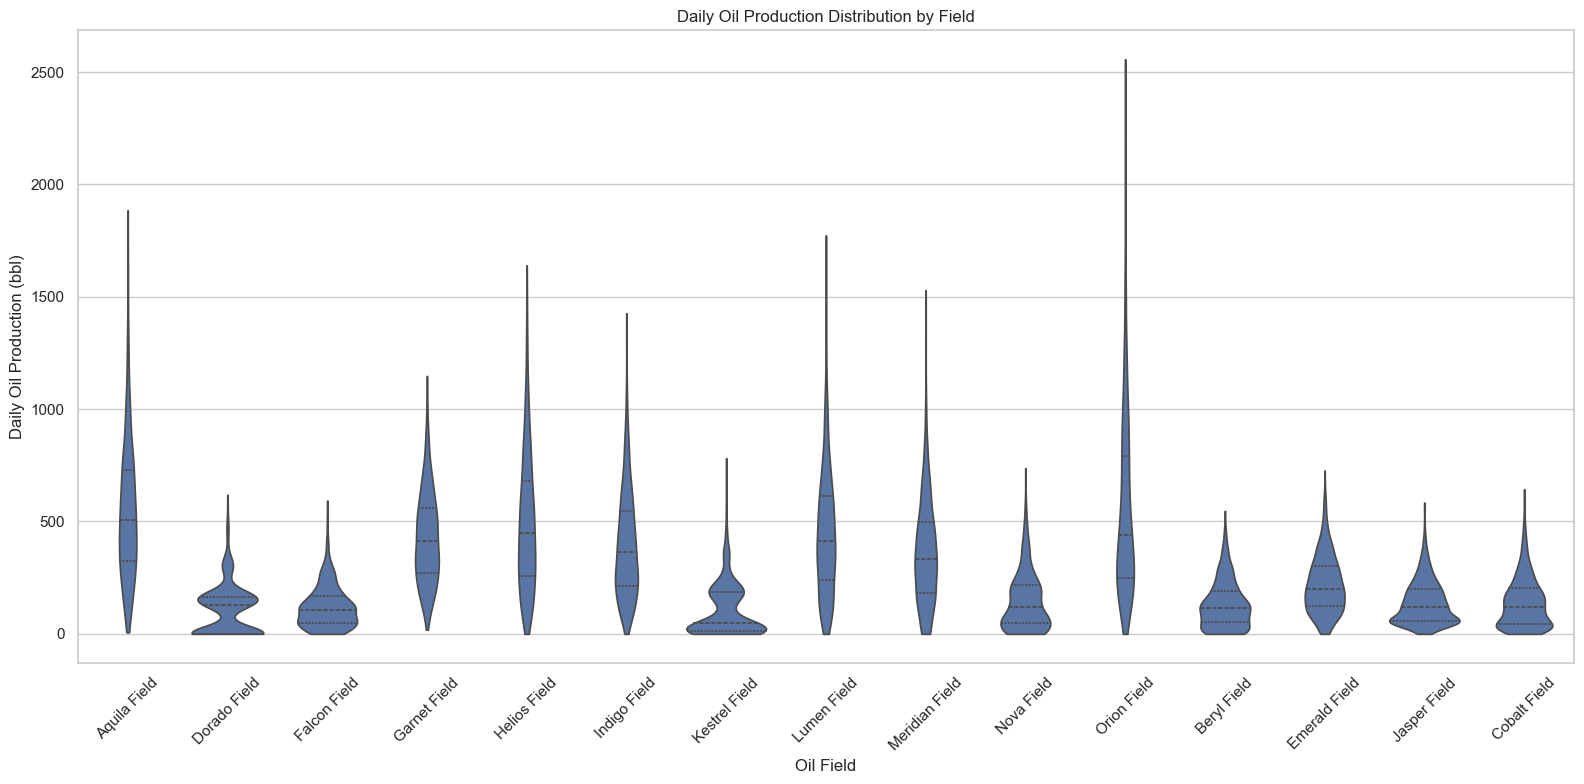

In [27]:
# violin plot to examine the shape of each field's production distribution:
plt.figure(figsize=(16, 8))

sns.violinplot(
    data=field_daily,
    x="field_name",
    y="daily_oil",
    inner="quartile",
    cut=0
)

plt.title("Daily Oil Production Distribution by Field")
plt.xlabel("Oil Field")
plt.ylabel("Daily Oil Production (bbl)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
# Compare field-level daily oil production distributions
from scipy.stats import levene, kruskal
import pandas as pd

field_groups = [
    group["daily_oil"].dropna().to_numpy()
    for _, group in field_daily.groupby("field_name")
]

field_names = list(field_daily.groupby("field_name").groups.keys())

if len(field_groups) < 2 or any(len(group) == 0 for group in field_groups):
    raise ValueError("At least two non-empty field groups are required.")

# Levene's test with median centring (Brown-Forsythe variant)
levene_stat, levene_p = levene(*field_groups, center="median")

# Kruskal-Wallis rank test across all field groups
kruskal_stat, kruskal_p = kruskal(*field_groups)

print("LEVENE'S TEST (MEDIAN-CENTRED)")
print("Statistic:", round(levene_stat, 4))
print("P-value:", f"{levene_p:.6g}")

print("\\nKRUSKAL-WALLIS TEST")
print("Statistic:", round(kruskal_stat, 4))
print("P-value:", f"{kruskal_p:.6g}")

print(
    "\\nInterpretation note: Levene's test evaluates equality of group variances. "
    "Kruskal-Wallis tests whether the field groups have the same rank "
    "distribution; it is not automatically a test of medians unless the "
    "distribution shapes are comparable."
)
print(
    "Important design limitation: these are daily observations from the same "
    "fields over time. Serial dependence and common date effects may violate "
    "the independence assumption of the standard tests. Treat the results as "
    "exploratory comparisons, not definitive independent-sample inference."
)

LEVENE'S TEST (MEDIAN-CENTRED)
Statistic: 280.8293
P-value: 0
\nKRUSKAL-WALLIS TEST
Statistic: 6458.6984
P-value: 0
\nInterpretation note: Levene's test evaluates equality of group variances. Kruskal-Wallis tests whether the field groups have the same rank distribution; it is not automatically a test of medians unless the distribution shapes are comparable.
Important design limitation: these are daily observations from the same fields over time. Serial dependence and common date effects may violate the independence assumption of the standard tests. Treat the results as exploratory comparisons, not definitive independent-sample inference.


In [29]:
# Pairwise field comparisons: Mann-Whitney U with Holm adjustment
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import pandas as pd
import numpy as np

field_data = {
    name: group["daily_oil"].dropna().to_numpy()
    for name, group in field_daily.groupby("field_name")
}

results = []

for field1, field2 in combinations(sorted(field_data.keys()), 2):
    values1 = field_data[field1]
    values2 = field_data[field2]

    if len(values1) == 0 or len(values2) == 0:
        continue

    # U is reported for the first sample (field1).
    statistic, p_value = mannwhitneyu(
        values1,
        values2,
        alternative="two-sided",
        method="asymptotic"
    )

    n1, n2 = len(values1), len(values2)

    # Rank-biserial correlation, oriented as Field 1 relative to Field 2.
    # Positive: values from Field 1 tend to rank higher than Field 2.
    # Negative: values from Field 1 tend to rank lower than Field 2.
    # Zero: no net rank dominance. Ties contribute half to each direction.
    rank_biserial = (2 * statistic / (n1 * n2)) - 1

    results.append({
        "Field 1": field1,
        "Field 2": field2,
        "N 1": n1,
        "N 2": n2,
        "Mean 1": values1.mean(),
        "Mean 2": values2.mean(),
        "Median 1": np.median(values1),
        "Median 2": np.median(values2),
        "Mean Difference (1 - 2)": values1.mean() - values2.mean(),
        "Median Difference (1 - 2)": np.median(values1) - np.median(values2),
        "Rank-Biserial r (1 vs 2)": rank_biserial,
        "Raw p-value": p_value
    })

pairwise_results = pd.DataFrame(results)

if pairwise_results.empty:
    raise ValueError("No valid pairwise field comparisons were generated.")

# Holm's step-down adjustment controls family-wise error across all pairwise tests.
reject, adjusted_p, _, _ = multipletests(
    pairwise_results["Raw p-value"],
    alpha=0.05,
    method="holm"
)

pairwise_results["Holm-adjusted p-value"] = adjusted_p
pairwise_results["Significant (Holm, 0.05)"] = reject

pairwise_results = pairwise_results.sort_values(
    "Holm-adjusted p-value"
).reset_index(drop=True)

display(pairwise_results.round(5))

print(
    "Effect-size direction: positive rank-biserial values indicate that Field 1 "
    "tends to have higher daily oil-production ranks than Field 2; negative "
    "values indicate the reverse. The sign changes if the field order is reversed."
)
print(
    "Design limitation: Mann-Whitney U assumes independent observations. "
    "Repeated daily measurements within fields may be serially dependent; "
    "therefore these pairwise results are exploratory and should not be "
    "interpreted as time-series-adjusted evidence."
)

,Field 1,Field 2,N 1,N 2,Mean 1,Mean 2,Median 1,Median 2,Mean Difference (1 - 2),Median Difference (1 - 2),Rank-Biserial r (1 vs 2),Raw p-value,Holm-adjusted p-value,"Significant (Holm, 0.05)"
0,Aquila Field,Kestrel Field,1087,899,547.00,105.42,507.15,47.23,441.58,459.92,0.88,0.00,0.00,True
1,Aquila Field,Falcon Field,1087,919,547.00,120.85,507.15,106.53,426.16,400.62,0.87,0.00,0.00,True
2,Aquila Field,Beryl Field,1087,1018,547.00,131.90,507.15,115.42,415.11,391.73,0.85,0.00,0.00,True
3,Falcon Field,Garnet Field,919,1092,120.85,427.56,106.53,411.11,-306.72,-304.57,-0.86,0.00,0.00,True
4,Garnet Field,Kestrel Field,1092,899,427.56,105.42,411.11,47.23,322.15,363.88,0.85,0.00,0.00,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,Helios Field,Orion Field,1080,1074,495.07,556.10,450.10,438.16,-61.02,11.94,-0.04,0.09,0.68,False
101,Beryl Field,Nova Field,1018,963,131.90,146.68,115.42,117.49,-14.79,-2.07,-0.03,0.28,0.95,False
102,Jasper Field,Nova Field,803,963,140.71,146.68,119.43,117.49,-5.97,1.94,0.03,0.24,0.95,False
103,Cobalt Field,Nova Field,897,963,140.15,146.68,120.63,117.49,-6.53,3.14,0.01,0.72,1.00,False


Effect-size direction: positive rank-biserial values indicate that Field 1 tends to have higher daily oil-production ranks than Field 2; negative values indicate the reverse. The sign changes if the field order is reversed.
Design limitation: Mann-Whitney U assumes independent observations. Repeated daily measurements within fields may be serially dependent; therefore these pairwise results are exploratory and should not be interpreted as time-series-adjusted evidence.


In [30]:
# quantify which fields are most consistent

field_stability = (
    field_daily.groupby("field_name")["daily_oil"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
)

field_stability["CV_pct"] = (
    field_stability["std"] / field_stability["mean"]
) * 100

field_stability["IQR"] = (
    field_stability["q3"] - field_stability["q1"]
)

field_stability = field_stability.sort_values("CV_pct")

display(field_stability.round(2))

,observations,mean,median,std,minimum,maximum,q1,q3,CV_pct,IQR
field_name,,,,,,,,,,
Garnet Field,1092,427.56,411.10,202.83,18.56,"1,147.63",270.37,558.26,47.44,287.88
Aquila Field,1087,547.00,507.15,306.12,6.86,"1,885.22",324.54,730.06,55.96,405.51
Emerald Field,1088,219.86,199.84,128.17,0.00,726.44,123.76,300.38,58.30,176.62
Indigo Field,1012,401.09,364.07,245.33,0.00,"1,426.52",212.57,548.76,61.17,336.19
Lumen Field,1089,445.80,411.87,274.77,0.00,"1,772.99",237.80,612.10,61.64,374.30
Helios Field,1080,495.07,450.10,305.91,0.00,"1,639.71",257.46,680.46,61.79,423.01
Meridian Field,1062,364.28,334.58,232.73,0.00,"1,529.69",181.25,499.38,63.89,318.12
Jasper Field,803,140.71,119.43,96.76,0.00,583.77,58.77,197.32,68.77,138.56
Orion Field,1074,556.10,438.16,402.98,0.00,"2,557.21",250.27,793.26,72.46,542.99


In [31]:
# Monthly production stability by field
# The source data run through November 2026; exclude November and later
# because November is incomplete at the time this analysis was prepared.
completed_daily = field_daily[
    field_daily["production_date"] < pd.Timestamp("2026-11-01")
].copy()

completed_daily["month"] = (
    completed_daily["production_date"].dt.to_period("M")
)

monthly_field = (
    completed_daily
    .groupby(["month", "field_name"], as_index=False)
    .agg(
        monthly_oil=("daily_oil", "sum"),
        observed_daily_records=("daily_oil", "count")
    )
)

monthly_stability = (
    monthly_field
    .groupby("field_name")["monthly_oil"]
    .agg(
        months_observed="count",
        mean_monthly_oil="mean",
        median_monthly_oil="median",
        std_monthly_oil="std",
        minimum="min",
        maximum="max"
    )
)

monthly_stability["CV_pct"] = (
    monthly_stability["std_monthly_oil"]
    / monthly_stability["mean_monthly_oil"].replace(0, np.nan)
) * 100

monthly_stability = monthly_stability.sort_values("CV_pct")
display(monthly_stability.round(2))

print(
    "Coverage note: monthly totals are calculated from available field-day "
    "records. A missing field-month is not assumed to represent zero production; "
    "the coefficient of variation therefore describes observed monthly totals "
    "and may be affected by incomplete coverage."
)

,months_observed,mean_monthly_oil,median_monthly_oil,std_monthly_oil,minimum,maximum,CV_pct
field_name,,,,,,,
Garnet Field,34,"13,060.62","13,219.31","1,181.81","10,104.56","15,362.94",9.05
Emerald Field,34,"6,665.22","6,642.73",707.36,"5,455.47","8,321.93",10.61
Aquila Field,34,"16,604.18","16,561.58","1,783.85","12,193.23","21,022.12",10.74
Indigo Field,34,"11,263.74","11,342.90","1,265.37","8,731.44","14,012.93",11.23
Meridian Field,34,"10,778.05","10,585.92","1,330.17","7,325.20","13,374.96",12.34
Helios Field,34,"14,991.98","14,743.75","1,927.01","11,357.31","21,611.77",12.85
Orion Field,34,"16,521.80","16,319.80","2,148.19","12,697.05","23,472.53",13.00
Lumen Field,34,"13,581.87","13,642.48","1,881.20","10,016.45","17,845.99",13.85
Beryl Field,34,"3,703.80","3,672.10",555.35,"2,567.63","4,702.69",14.99


Coverage note: monthly totals are calculated from available field-day records. A missing field-month is not assumed to represent zero production; the coefficient of variation therefore describes observed monthly totals and may be affected by incomplete coverage.


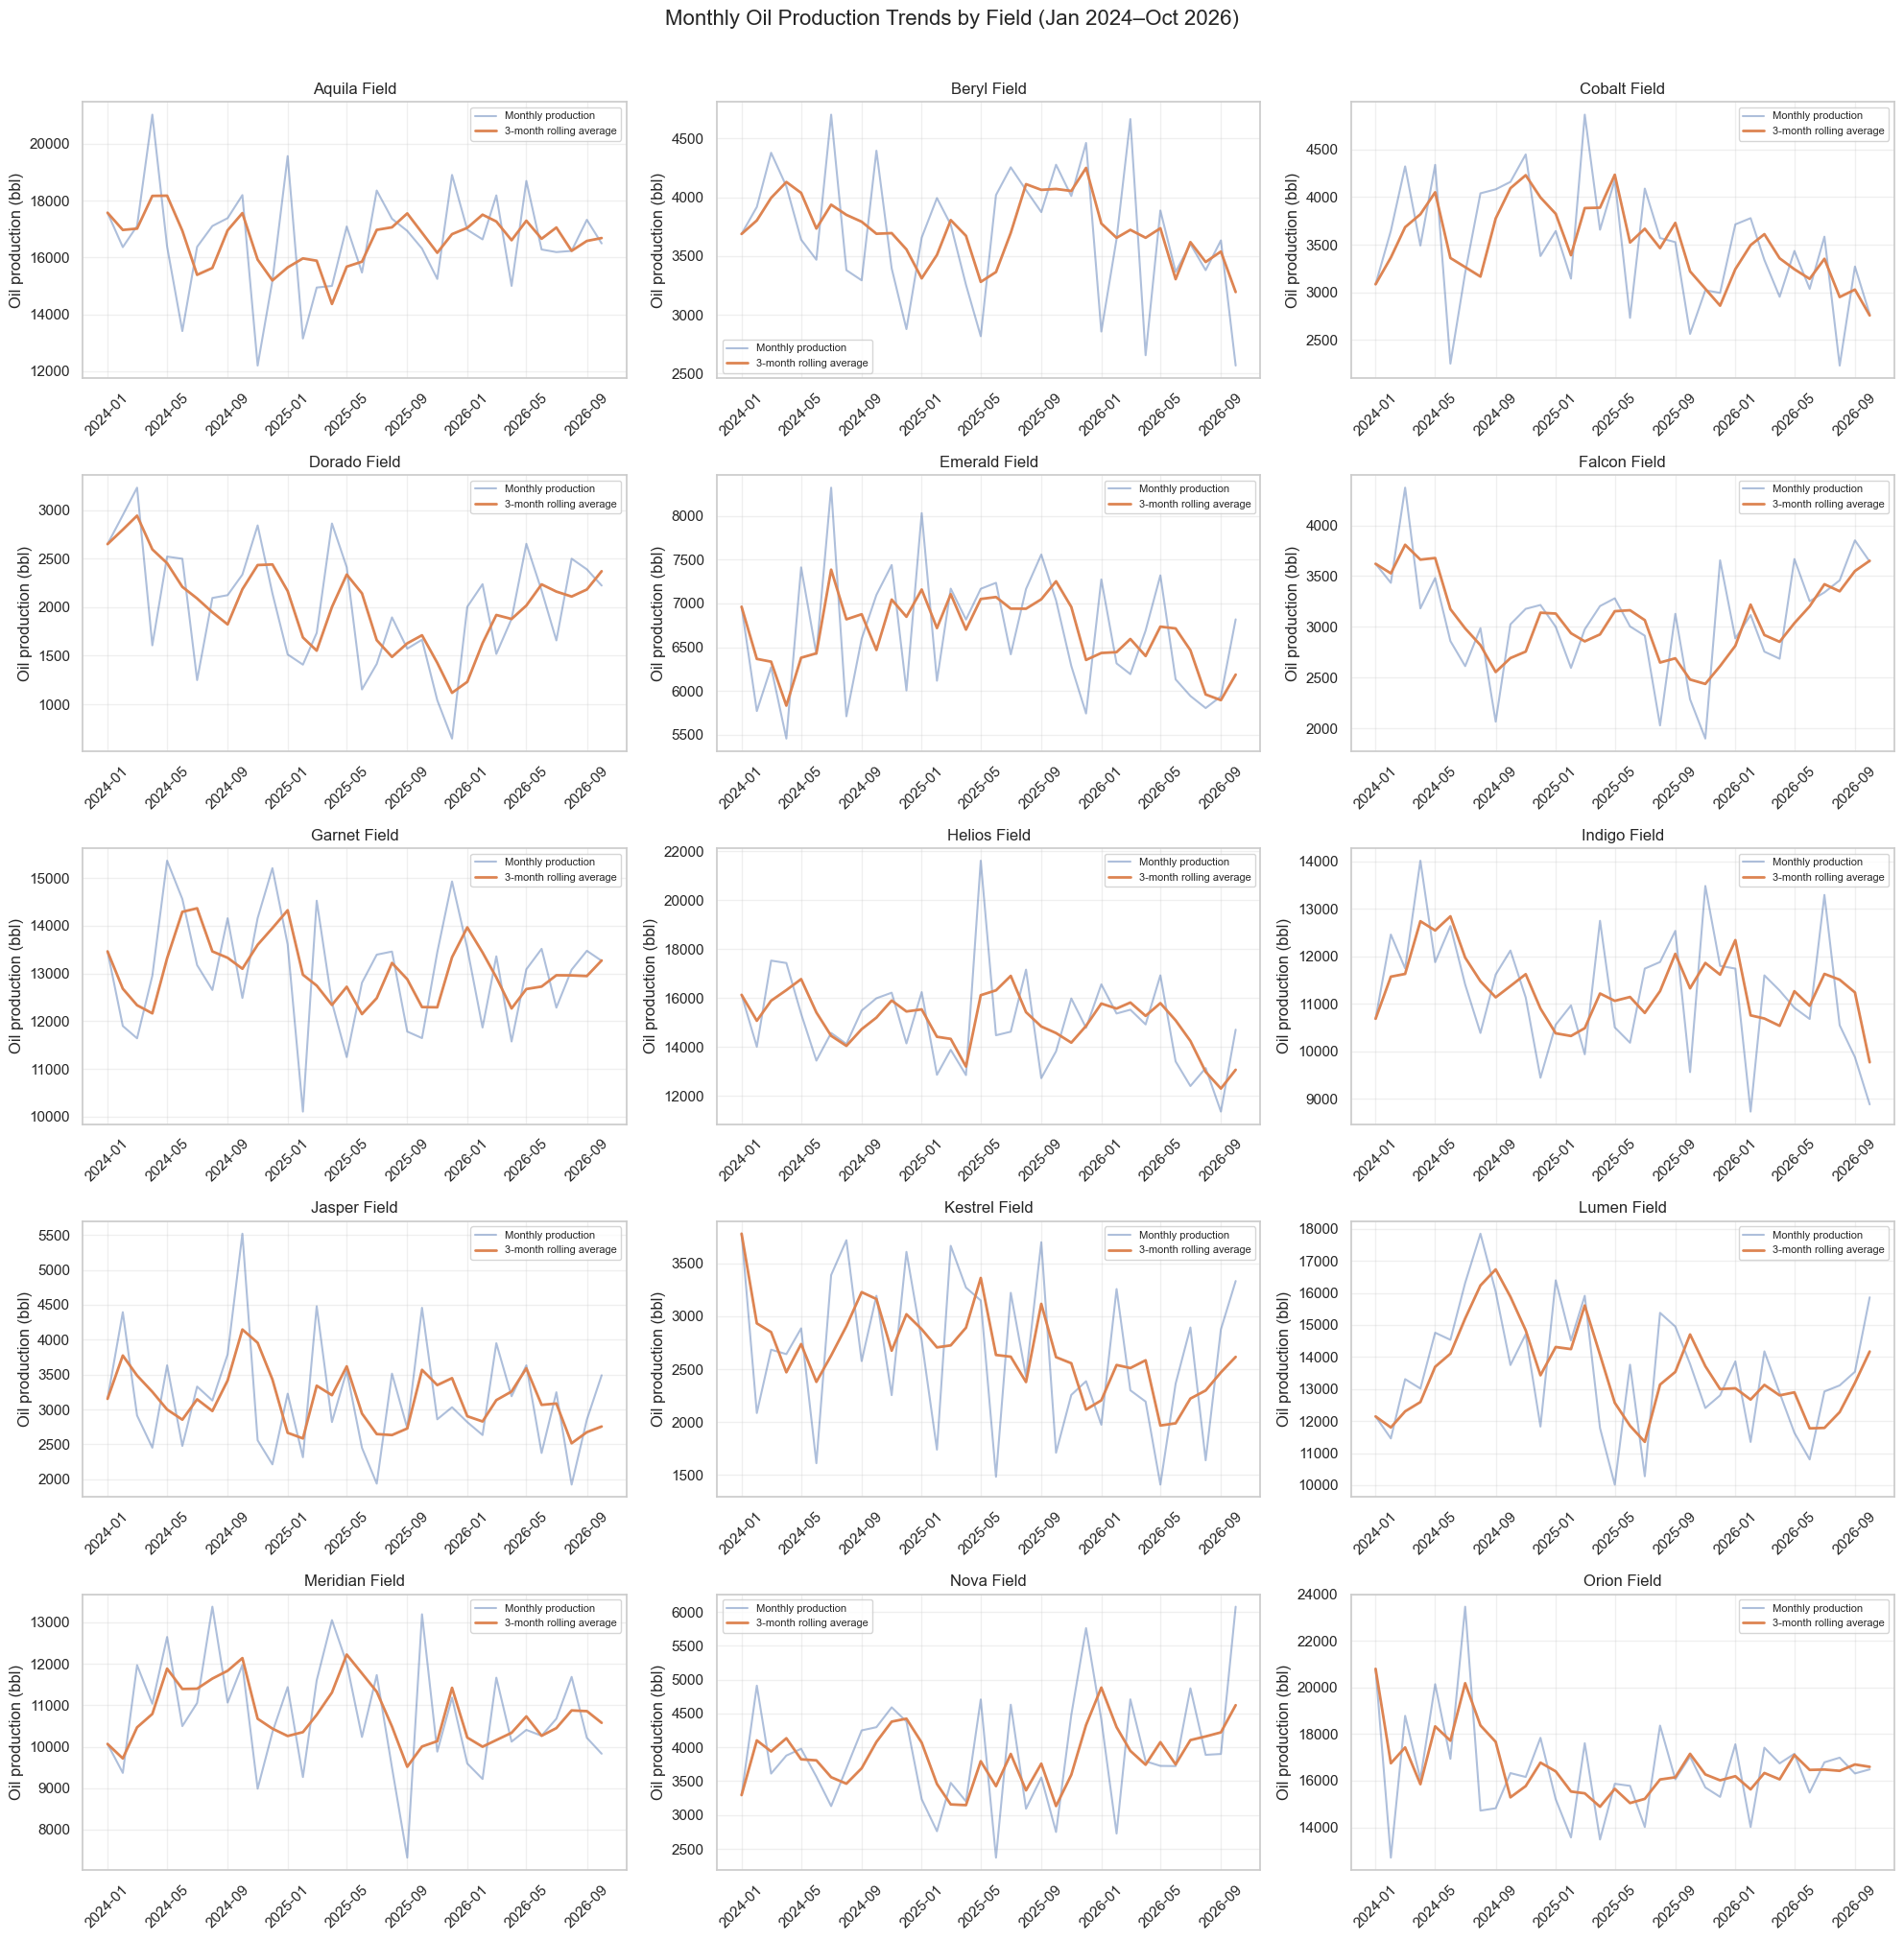

In [32]:
# Visualise monthly production trends by field
import matplotlib.pyplot as plt
import pandas as pd
import math

monthly_field = monthly_field.sort_values(
    ["field_name", "month"]
).copy()

monthly_field["rolling_3m"] = (
    monthly_field
    .groupby("field_name")["monthly_oil"]
    .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

monthly_field["plot_month"] = monthly_field["month"].dt.to_timestamp()
fields = sorted(monthly_field["field_name"].unique())

ncols = 3
nrows = math.ceil(len(fields) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(20, 4 * nrows),
    squeeze=False
)
axes = axes.flatten()

for i, field in enumerate(fields):
    field_data = monthly_field[monthly_field["field_name"] == field]

    axes[i].plot(
        field_data["plot_month"],
        field_data["monthly_oil"],
        label="Monthly production",
        alpha=0.45
    )
    axes[i].plot(
        field_data["plot_month"],
        field_data["rolling_3m"],
        label="3-month rolling average",
        linewidth=2
    )
    axes[i].set_title(field)
    axes[i].set_ylabel("Oil production (bbl)")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=8)

for ax in axes[len(fields):]:
    ax.set_visible(False)

plt.suptitle(
    "Monthly Oil Production Trends by Field (Jan 2024–Oct 2026)",
    fontsize=16,
    y=1.01
)
plt.tight_layout()
plt.show()

In [33]:
# Estimate linear monthly production trends by field
from scipy.stats import linregress
import numpy as np
import pandas as pd

trend_results = []

for field, group in monthly_field.groupby("field_name"):
    group = group.sort_values("month").copy()

    # Use calendar-month indices, not row positions, so gaps do not compress time.
    month_index = group["month"].map(lambda period: period.year * 12 + period.month)
    x = (month_index - month_index.min()).to_numpy(dtype=float)
    y = group["monthly_oil"].to_numpy(dtype=float)

    if len(y) < 3 or np.unique(x).size < 2:
        continue

    regression = linregress(x, y)
    mean_production = y.mean()

    first_3_observed_avg = y[:3].mean()
    last_3_observed_avg = y[-3:].mean()

    change_pct = (
        (last_3_observed_avg - first_3_observed_avg)
        / first_3_observed_avg * 100
        if first_3_observed_avg != 0 else np.nan
    )

    trend_results.append({
        "field_name": field,
        "months_observed": len(y),
        "first_observed_month": str(group["month"].iloc[0]),
        "last_observed_month": str(group["month"].iloc[-1]),
        "mean_monthly_oil": mean_production,
        "monthly_slope_bbl": regression.slope,
        "slope_pct_of_mean_per_month": (
            regression.slope / mean_production * 100
            if mean_production != 0 else np.nan
        ),
        "first_3_observed_month_avg": first_3_observed_avg,
        "last_3_observed_month_avg": last_3_observed_avg,
        "first_last_change_pct": change_pct,
        "r_squared": regression.rvalue ** 2,
        "p_value": regression.pvalue
    })

field_trends = pd.DataFrame(trend_results).sort_values(
    "monthly_slope_bbl"
).reset_index(drop=True)

display(field_trends.round(3))

print(
    "Interpretation note: the slope is the fitted linear change in monthly oil "
    "production (bbl) per calendar month. The p-value is from ordinary least "
    "squares and assumes independent, homoscedastic errors; monthly production "
    "series may be autocorrelated, so inferential p-values are exploratory."
)
print(
    "The first/last three-month comparison uses the first and last three "
    "observed field-months, which may not be consecutive if months are missing."
)

,field_name,months_observed,first_observed_month,last_observed_month,mean_monthly_oil,monthly_slope_bbl,slope_pct_of_mean_per_month,first_3_observed_month_avg,last_3_observed_month_avg,first_last_change_pct,r_squared,p_value
0,Helios Field,34,2024-01,2026-10,"14,991.98",-49.96,-0.33,"15,888.72","13,066.98",-17.76,0.07,0.14
1,Orion Field,34,2024-01,2026-10,"16,521.80",-38.92,-0.24,"17,428.87","16,596.49",-4.78,0.03,0.31
2,Lumen Field,34,2024-01,2026-10,"13,581.87",-38.00,-0.28,"12,302.40","14,169.88",15.18,0.04,0.25
3,Indigo Field,34,2024-01,2026-10,"11,263.74",-36.07,-0.32,"11,629.54","9,769.50",-15.99,0.08,0.10
4,Meridian Field,34,2024-01,2026-10,"10,778.05",-26.10,-0.24,"10,466.34","10,575.63",1.04,0.04,0.27
5,Cobalt Field,34,2024-01,2026-10,"3,486.41",-23.27,-0.67,"3,683.74","2,757.59",-25.14,0.14,0.03
6,Kestrel Field,34,2024-01,2026-10,"2,660.43",-16.42,-0.62,"2,850.45","2,616.04",-8.22,0.05,0.19
7,Dorado Field,34,2024-01,2026-10,"2,022.98",-15.30,-0.76,"2,942.23","2,370.15",-19.44,0.06,0.15
8,Beryl Field,34,2024-01,2026-10,"3,703.80",-12.85,-0.35,"3,994.46","3,193.23",-20.06,0.05,0.19
9,Jasper Field,34,2024-01,2026-10,"3,148.77",-11.83,-0.38,"3,486.57","2,756.35",-20.94,0.02,0.40


Interpretation note: the slope is the fitted linear change in monthly oil production (bbl) per calendar month. The p-value is from ordinary least squares and assumes independent, homoscedastic errors; monthly production series may be autocorrelated, so inferential p-values are exploratory.
The first/last three-month comparison uses the first and last three observed field-months, which may not be consecutive if months are missing.


## Statistical interpretation and limitations

This notebook analyses the synthetic daily production records exposed through `analytics.vw_production_daily`. The dataset contains repeated observations over time for multiple fields and facilities.

- Descriptive statistics, distributions, IQR flags, monthly aggregation, and exploratory visualisations describe the supplied records; an IQR flag is not proof of a data error.
- Pearson correlation measures linear association; Spearman correlation measures monotonic rank association. Neither establishes causation.
- The Fisher-z confidence intervals are approximate Pearson-correlation intervals and do not adjust for serial dependence.
- Levene's median-centred test assesses variance differences. Kruskal-Wallis assesses differences in rank distributions; interpreting it as a median test requires comparable distribution shapes.
- Mann-Whitney pairwise tests and the Kruskal-Wallis/Levene tests use standard independent-group assumptions. Daily observations from the same fields can be serially dependent, so these comparisons are exploratory rather than definitive time-series inference.
- Holm adjustment is applied to the eight correlation tests and separately to the family of pairwise field comparisons.
- Rank-biserial effect sizes are signed relative to the displayed Field 1 / Field 2 order.
- Linear trend slopes use calendar-month spacing. Ordinary least-squares p-values do not account for possible autocorrelation.
- The dataset is synthetic and should not be represented as actual operator performance, financial, production, or HSE data.
